<a href="https://colab.research.google.com/github/lakkshanarams-maker/language-Specification/blob/main/language_specifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully!")

TensorFlow version: 2.21.0
Libraries imported successfully!


In [3]:
from google.colab import files
import os
import glob
import zipfile
import pandas as pd

uploaded = files.upload()

# Check if any .zip or .csv files were uploaded
zip_files = [f for f in uploaded if f.endswith(".zip")]
csv_files = [f for f in uploaded if f.endswith(".csv")]

if zip_files:
    with zipfile.ZipFile(zip_files[0], "r") as z:
        z.extractall("/content/language_dataset")

    # If we extracted a zip, look for CSV files inside the extracted folder
    csv_paths = glob.glob(
        "/content/language_dataset/**/*.csv",
        recursive=True
    )
else:
    # Otherwise, use the directly uploaded CSV files from the current workspace
    csv_paths = csv_files

print("CSV files found:", csv_paths)

if not csv_paths:
    raise FileNotFoundError(
        "No CSV file found. Please upload either a CSV file or a ZIP containing CSVs."
    )

# Load the first detected CSV
df = pd.read_csv(csv_paths[0], encoding="utf-8")
print("Dataset loaded successfully!")
print(df.head())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Saving dataset.csv to dataset (1).csv
CSV files found: ['dataset (1).csv']
Dataset loaded successfully!
                                                Text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas  på eng the jesuit...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch
Shape: (22000, 2)
Columns: ['Text', 'language']


In [4]:
# Identify text and language columns
text_candidates = ["text", "Text", "sentence", "Sentence"]
label_candidates = [
    "language", "Language", "lang", "Lang", "label", "Label"
]

text_col = next(
    (c for c in text_candidates if c in df.columns), None
)
label_col = next(
    (c for c in label_candidates if c in df.columns), None
)

if text_col is None or label_col is None:
    raise ValueError(
        "Could not identify columns. Check df.columns and set "
        "text_col and label_col manually."
    )

data = df[[text_col, label_col]].copy()
data.columns = ["text", "language"]

# Handle missing values and empty text
data = data.dropna(subset=["text", "language"])
data["text"] = data["text"].astype(str).str.strip()
data["language"] = data["language"].astype(str).str.strip()

data = data[
    (data["text"] != "") &
    (data["language"] != "")
]

# Remove duplicate samples
data = data.drop_duplicates(subset=["text", "language"])

# Select a manageable, balanced subset
data = (
    data.groupby("language", group_keys=False)
    .head(500)
    .reset_index(drop=True)
)

print("Missing values:\n", data.isnull().sum())
print("\nNumber of samples:", len(data))
print("Number of languages:", data["language"].nunique())
print("\nSamples per language:\n", data["language"].value_counts())

data.head()

Missing values:
 text        0
language    0
dtype: int64

Number of samples: 11000
Number of languages: 22

Samples per language:
 language
Estonian      500
Swedish       500
Thai          500
Tamil         500
Dutch         500
Japanese      500
Turkish       500
Latin         500
Urdu          500
Indonesian    500
Portugese     500
French        500
Chinese       500
Korean        500
Hindi         500
Spanish       500
Pushto        500
Persian       500
Romanian      500
Russian       500
English       500
Arabic        500
Name: count, dtype: int64


,text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch


In [5]:
import re

def preprocess_text(text):
    text = text.lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

data["text"] = data["text"].apply(preprocess_text)

# Remove texts that became empty
data = data[data["text"].str.len() > 0].reset_index(drop=True)

print(data.head())

                                                text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas på eng the jesuits...   Swedish
2  ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...      Thai
3  விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch


In [6]:
label_encoder = LabelEncoder()

y = label_encoder.fit_transform(data["language"])
X = data["text"].values

num_classes = len(label_encoder.classes_)

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_text, X_val_text, y_train, y_val = train_test_split(
    X_train_text, y_train,
    test_size=0.10,
    random_state=42,
    stratify=y_train
)

print("Training samples:", len(X_train_text))
print("Validation samples:", len(X_val_text))
print("Testing samples:", len(X_test_text))
print("Number of languages:", num_classes)
print("Languages:", label_encoder.classes_)

Training samples: 7920
Validation samples: 880
Testing samples: 2200
Number of languages: 22
Languages: ['Arabic' 'Chinese' 'Dutch' 'English' 'Estonian' 'French' 'Hindi'
 'Indonesian' 'Japanese' 'Korean' 'Latin' 'Persian' 'Portugese' 'Pushto'
 'Romanian' 'Russian' 'Spanish' 'Swedish' 'Tamil' 'Thai' 'Turkish' 'Urdu']


In [7]:
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train = pad_sequences(
    tokenizer.texts_to_sequences(X_train_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_val = pad_sequences(
    tokenizer.texts_to_sequences(X_val_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    tokenizer.texts_to_sequences(X_test_text),
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

print("Training sequence shape:", X_train.shape)
print("Validation sequence shape:", X_val.shape)
print("Testing sequence shape:", X_test.shape)

Training sequence shape: (7920, 100)
Validation sequence shape: (880, 100)
Testing sequence shape: (2200, 100)


In [15]:
model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(num_classes, activation="softmax")
])

model.build(input_shape=(None, MAX_LEN))

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 22)             │           726 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,315,830 (5.02 MB)

 Trainable params: 1,315,830 (5.02 MB)

 Non-trainable params: 0 (0.00 B)

In [9]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=8,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 17s 113ms/step - accuracy: 0.2206 - loss: 2.5580 - val_accuracy: 0.5034 - val_loss: 1.7177
Epoch 2/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 21s 169ms/step - accuracy: 0.5090 - loss: 1.5747 - val_accuracy: 0.7659 - val_loss: 1.0324
Epoch 3/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - accuracy: 0.7130 - loss: 0.9414 - val_accuracy: 0.8227 - val_loss: 0.6998
Epoch 4/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 13s 108ms/step - accuracy: 0.7732 - loss: 0.6973 - val_accuracy: 0.8841 - val_loss: 0.4933
Epoch 5/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 109ms/step - accuracy: 0.8422 - loss: 0.4905 - val_accuracy: 0.8534 - val_loss: 0.4374
Epoch 6/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 113ms/step - accuracy: 0.8749 - loss: 0.4166 - val_accuracy: 0.8989 - val_loss: 0.3766
Epoch 7/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 14s 110ms/step - accuracy: 0.9015 - loss: 0.3328 - val_accuracy: 0.9182 - val_loss: 0.3402
Epoch 8/8
124/124 ━━━━━━━━━━━━━━━━━━━━ 22s 120ms/step - accuracy: 0.9210 - loss: 0.2439 - 

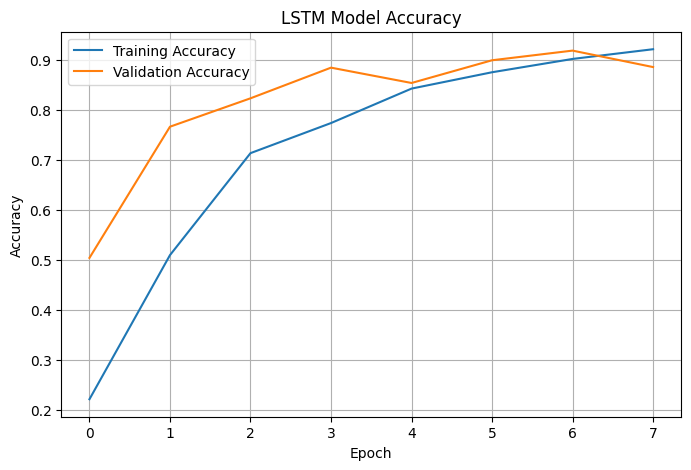

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("LSTM Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average="macro", zero_division=0
)

recall = recall_score(
    y_test, y_pred, average="macro", zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("MODEL EVALUATION RESULTS")
print("-" * 35)
print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-Score  : {f1:.4f}")

print("\nDetailed Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

MODEL EVALUATION RESULTS
-----------------------------------
Accuracy  : 0.9150
Precision : 0.9163
Recall    : 0.9150
F1-Score  : 0.9141

Detailed Classification Report:

              precision    recall  f1-score   support

      Arabic       1.00      0.94      0.97       100
     Chinese       0.48      0.57      0.52       100
       Dutch       0.96      0.97      0.97       100
     English       0.94      0.94      0.94       100
    Estonian       0.96      0.96      0.96       100
      French       0.97      1.00      0.99       100
       Hindi       0.99      0.97      0.98       100
  Indonesian       1.00      0.98      0.99       100
    Japanese       0.46      0.33      0.38       100
      Korean       0.97      1.00      0.99       100
       Latin       0.96      0.90      0.93       100
     Persian       1.00      1.00      1.00       100
   Portugese       1.00      0.98      0.99       100
      Pushto       0.96      0.91      0.93       100
    Romanian      

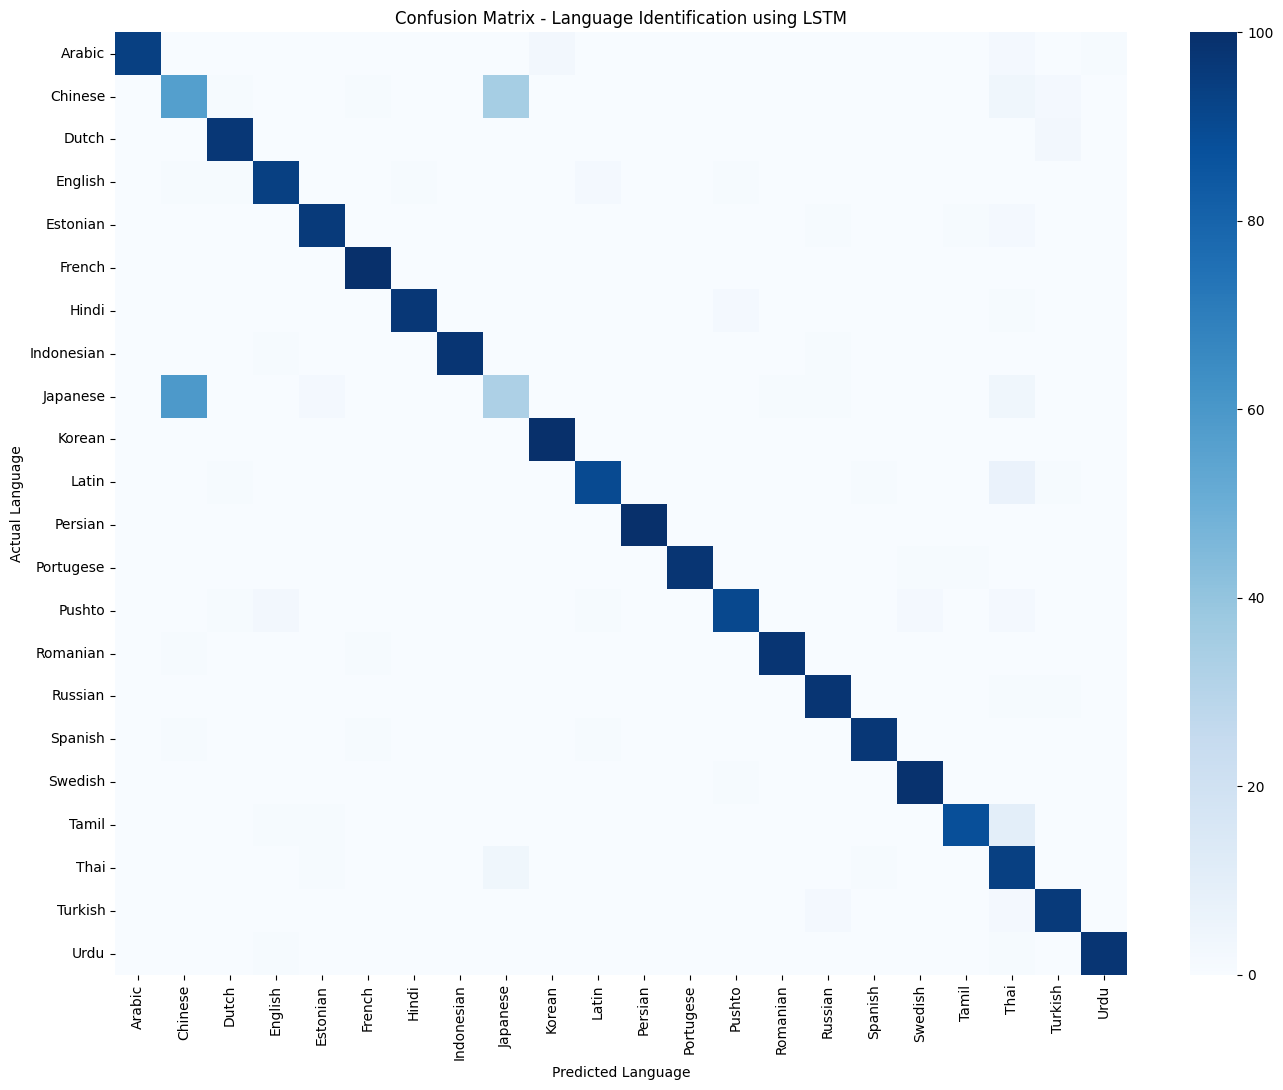

In [12]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 11))

sns.heatmap(
    cm,
    annot=True if num_classes <= 12 else False,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Confusion Matrix - Language Identification using LSTM")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
unseen_texts = [
    "Hello, how are you? I hope you are doing well.",
    "Bonjour, comment allez-vous aujourd'hui ?",
    "Hola, ¿cómo estás? Espero que tengas un buen día.",
    "Guten Tag, wie geht es Ihnen heute?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?"
]

def predict_language(texts):
    cleaned_texts = [preprocess_text(t) for t in texts]

    sequences = tokenizer.texts_to_sequences(cleaned_texts)

    padded = pad_sequences(
        sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)
    predicted_ids = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    for i, text in enumerate(texts):
        language = label_encoder.inverse_transform(
            [predicted_ids[i]]
        )[0]

        print("Text:", text)
        print("Predicted language:", language)
        print(f"Model confidence: {confidence[i]:.2%}")
        print("-" * 60)

predict_language(unseen_texts)

Text: Hello, how are you? I hope you are doing well.
Predicted language: Hindi
Model confidence: 31.75%
------------------------------------------------------------
Text: Bonjour, comment allez-vous aujourd'hui ?
Predicted language: Japanese
Model confidence: 49.03%
------------------------------------------------------------
Text: Hola, ¿cómo estás? Espero que tengas un buen día.
Predicted language: French
Model confidence: 46.46%
------------------------------------------------------------
Text: Guten Tag, wie geht es Ihnen heute?
Predicted language: Chinese
Model confidence: 40.30%
------------------------------------------------------------
Text: வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?
Predicted language: Japanese
Model confidence: 49.54%
------------------------------------------------------------
